In [1]:
%matplotlib inline

In [8]:
import sys
sys.path.append("/global/cfs/projectdirs/m4491/btaczak/SOLPS-BOUT-coupling/scripts")
import os
import sys
import yaml
import numpy as np
from pathlib import Path
import re
import numpy as np
import netCDF4 as nc
import yaml
from scipy.interpolate import interp1d
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from boutdata.data import BoutData
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, fixed
from sibil_io_functions import load_config, sibil_config_summary, confirm, parse_tdata2, parse_block_sizes, write_updated_namelist, _format_value, extract_tdata_first_index, interpolate_dataset, get_midplane_distances_from_psin, vec_summary, set_tdata2_block, get_bout_midplane_distances
from converged_profile_functions import unbiased_convergence, end_biased_convergence

DEFAULT_CONFIG_PATH = "SIBIL_config.yaml"

config_path = DEFAULT_CONFIG_PATH

if not os.path.exists(config_path):
    print(f"Error: config file not found: {config_path}")
    sys.exit(1)

config = load_config(config_path)
sibil_config_summary(config)

# if not confirm():
#     print("Aborted. No changes made.")
#     sys.exit(0)

import sibil  # imported here so summary/confirmation works without dependency installed

INPUT_FILE  = f"{config["base_path"]}/{config["iteration"]}_iteration/b2.transport.inputfile"
OUTPUT_FILE = f"{config["base_path"]}/{int(config["iteration"])+1}_iteration/b2.transport.inputfile"
bout_dir  = Path(f"{config["base_path"]}/{config["iteration"]}_iteration/{config["files"]["bout_dir"]}")
data_dir  = bout_dir / "numpy"
grid_fname= Path(f"{config["base_path"]}/{config["iteration"]}_iteration/{config["files"]["bgrid"]}")
grid_fname = str(grid_fname)
transport_coeffs = config["bout_to_solps_pass"]["passed_coeffs"]
profile_sample_timestep = config["bout_to_solps_pass"]["profile_sample_timestep"]
jomp = config["bout_to_solps_pass"]["jomp"]
N, l = config["bout_to_solps_pass"]["N"], config["bout_to_solps_pass"]["l"]

grid = DataFile(grid_fname)
try:
    _ = grid["psi_bdry"]
    has_psi_bdry = True
except Exception:
    has_psi_bdry = False
    
if has_psi_bdry:
    psi_bndry = grid["psi_bdry"]
else:
    psi_bndry = grid["psi_bndry"]

psin = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:,jomp]

sepx_dists_solps = extract_tdata_first_index(INPUT_FILE)
psin_mid, sepx_dists_bout = get_bout_midplane_distances(grid_fname)

convergent_transport_coeffs = {}
interplted_transport_coeffs = {}
# "ddr_Tetot_txy", "ddr_Titot_txy", 
#                                        "ddr_nitot_txy", 
transport_coeffs = transport_coeffs + [#"Vr_t",
                                       "ddr_Tetot_txy", "ddr_Titot_txy", 
                                       "ddr_nitot_txy", 
                                       #"Vexbx_txy", "Vbtildx_txy"
]
for var_name in transport_coeffs:
    var = np.load(f"{data_dir}/{var_name}.npy")
    var_conv = unbiased_convergence(var, N, l)
    var_conv_midplane = var_conv[profile_sample_timestep,:,jomp]
    var_conv_interpolated = interpolate_dataset(sepx_dists_bout,var_conv_midplane,sepx_dists_solps)
    nan_mask = np.isnan(var_conv_interpolated)
    var_conv_interpolated[nan_mask]=0
    
    convergent_transport_coeffs[var_name] = var_conv
    interplted_transport_coeffs[var_name] = var_conv_interpolated

SIBIL Midplane Mapper — Configuration Summary
  G-file         : ../g184016.03200  [OK]
  Geometry file  : ../baserun/HvsD_Dmesh_noC_v1.v001.geo  [OK]
  B-grid file    : Shelf_new_grid2_sinks2_gradfix/d3d_shelf_184016.03200_nc3.grd.nc  [OK]
  b2fstate       : b2fstate  [OK]
  b2fplasmf      : b2fplasmf  [OK]
  b2fgmtry       : b2fgmtry  [OK]

  Softmax scales (max, min):
    ni  : max=1e+16, min=1e+15
    ne  : max=1e+16, min=1e+15
    Ti  : max=0.5, min=0.0001
    Te  : max=0.5, min=0.0001


In [9]:
convergent_transport_coeffs["Da_t"].shape

(15, 260, 64)

In [10]:
# -----------------------------------------------------------------------------
# 2) AUTO-DETECT SHAPES
# -----------------------------------------------------------------------------
# Poloidal size = last axis of any array
#n_pol = convergent_transport_coeffs["Da_t"].shape[-1]
n_pol = convergent_transport_coeffs["Da_t"].shape[-1]

# Does anything (including psin) carry a time axis?
has_time = any(a.ndim == 3 for a in list(convergent_transport_coeffs.values()) + [psin])
n_time = None
if has_time:
    time_arrays = [a for a in list(convergent_transport_coeffs.values()) + [psin] if a.ndim == 3]
    n_time = time_arrays[0].shape[0]
    for a in time_arrays:
        assert a.shape[0] == n_time, "Mismatched n_time across arrays"


def get_slice(arr, j, t):
    """Return the 1D radial profile at poloidal index j (and time t if present)."""
    if arr.ndim == 3:
        return arr[t, :, j]
    else:
        return arr[:, j]

print(f"Timesteps: {n_time}")

Timesteps: 15


In [11]:
# PLOTTING
# -----------------------------------------------------------------------------
# 3) PLOT FUNCTION -- creates a brand-new figure each call (inline-friendly)
# -----------------------------------------------------------------------------
import os
import datetime
import numpy as np
import ipywidgets as widgets
from ipywidgets import interact, interactive_output, IntSlider, Text, Button, HBox, VBox, Output, fixed

colors = {"Da_t": "C0", "Xe_t": "C1", "Xi_t": "C2",
         "ddr_Tetot_txy": "C3", "ddr_Titot_txy": "C4", "ddr_nitot_txy": "C5", 
          "Vr_t": "C6", "Vexbx_txy": "C7", "Vbtildx_txy": "C8"}
labels = {"Da_t": r"$D$", "Xe_t": r"$\chi_e$", "Xi_t": r"$\chi_i$",
          "ddr_Tetot_txy": r"$\frac{\partial T_e}{\partial r}$",
          "ddr_Titot_txy": r"$\frac{\partial T_i}{\partial r}$",
          "ddr_nitot_txy": r"$\frac{\partial n_i}{\partial r}$",
          "Vr_t": r"$V_r$",
          "Vexbx_txy": r"$V_{E \times B}$",
          "Vbtildx_txy": r"$\tilde{V}_{b}$",
         }

# Directory where saved profile arrays will go. Adjust as needed.
SAVE_DIR = config["base_path"] if "config" in globals() else "."

# Keep track of the most-recently-plotted data + (j, t) so the
# save button can grab it without re-plotting.
_last_state = {"x": None, "data": None, "j": None, "t": None}

def plot_profiles(j, t=0):
    x = psin_mid

    fig, axs = plt.subplots(len(convergent_transport_coeffs), 1, figsize=(4,8), sharex=True)
    #fig, axs = plt.subplots(3, 1, figsize=(4, 5), sharex=True)

    data = {}
    for ax, name in zip(axs, convergent_transport_coeffs.keys()):
        y = get_slice(convergent_transport_coeffs[name], j, t)
        data[name] = y

        # if t == profile_sample_timestep:
        #     y_interp = interplted_transport_coeffs[name]
        #     x_interp = sepx_dists_solps
        #     ax.scatter(x_interp, y_interp, color=colors[name], label=labels[name])

        ax.plot(x, y, color=colors[name], label=labels[name])
        ax.set_ylabel(labels[name])
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis="x", labelsize=7)
        ax.tick_params(axis="y", labelsize=7)
        ax.yaxis.get_offset_text().set_fontsize(8)

    axs[2].set_xlabel(r"$\psi_n$")
    title = f"Poloidal index = {j}"
    if has_time:
        title += f"   |   Time index = {t}"
    # fig.suptitle(title)
    # fig.tight_layout()

    # Remember this data + indices so the Save button can use them later.
    _last_state["x"] = x
    _last_state["data"] = data
    _last_state["j"] = j
    _last_state["t"] = t

    plt.show()

# -----------------------------------------------------------------------------
# 4) SAVE BUTTON -- saves current profile arrays as "<lead>_<date>_<HH-MM-SS>.npz"
# -----------------------------------------------------------------------------
filename_lead = Text(
    value="profile",
    description="Filename lead:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="300px"),
)
save_button = Button(description="Save Profiles", button_style="success", icon="save")
save_output = Output()

def on_save_clicked(b):
    with save_output:
        save_output.clear_output()
        x = _last_state["x"]
        data = _last_state["data"]
        if x is None or data is None:
            print("Nothing to save yet -- move a slider first.")
            return

        now = datetime.datetime.now()
        date_str = now.strftime("%Y-%m-%d")
        time_str = now.strftime("%H-%M-%S")  # colons aren't filename-safe on all OSes
        lead = filename_lead.value.strip() or "profile"

        fname = f"{lead}_{date_str}_{time_str}.npz"
        outpath = os.path.join(SAVE_DIR, fname)

        np.savez(
            outpath,
            x=x,
            j=_last_state["j"],
            t=_last_state["t"],
            **data,  # Da_t, Xe_t, Xi_t arrays
        )
        print(f"Saved profile arrays to {outpath}")
        print(f"  keys: x, j, t, {', '.join(data.keys())}")

save_button.on_click(on_save_clicked)

# -----------------------------------------------------------------------------
# 5) WIRE UP SLIDERS -- run this cell once
# -----------------------------------------------------------------------------
j_slider = IntSlider(min=0, max=n_pol - 1, step=1, value=0, description="Pol. idx:")

if has_time:
    t_slider = IntSlider(min=0, max=l - 1, step=1, value=0, description="Time idx:")
else:
    t_slider = fixed(0)

plot_out = interactive_output(plot_profiles, {"j": j_slider, "t": t_slider})

controls = [j_slider]
if has_time:
    controls.append(t_slider)

ui = VBox([
    HBox(controls),
    plot_out,
    HBox([filename_lead, save_button]),
    save_output,
])

display(ui)


In [6]:
# ------------------------------------------------------------------
# Step 2: supply new values for each block as a 1-D array
#
# Replace the lists below with your actual arrays.
# Each list must have exactly N entries where N = ndata(1,1,k,l).
# ------------------------------------------------------------------

percentage = config["bout_to_solps_pass"]["percentage"] # percentage of the cross field transport that has a turbulent contribution

ls = config["bout_to_solps_pass"]["ls"]
alpha = config["bout_to_solps_pass"]["alpha"]

tdata2 = parse_tdata2(INPUT_FILE)
block_sizes = parse_block_sizes(INPUT_FILE)
for l in ls:
    if "Da_t" in transport_coeffs:
        # set particle density-driven diffusivity
        set_tdata2_block(tdata2,block_sizes,alpha,k=1,l=l,turbulent_profile=interplted_transport_coeffs["Da_t"],percentage=percentage)
    
    if "Xi_t" in transport_coeffs:
        # set ion thermal anomalous diffusivity
        set_tdata2_block(tdata2,block_sizes,alpha,k=3,l=l,turbulent_profile=interplted_transport_coeffs["Xi_t"],percentage=percentage)

if "Xi_t" in transport_coeffs:
    # set electron thermal anomalous diffusivity
    set_tdata2_block(tdata2,block_sizes,alpha,k=4,l=1,turbulent_profile=interplted_transport_coeffs["Xe_t"],percentage=percentage)

# ------------------------------------------------------------------
# Step 3: write
# ------------------------------------------------------------------
write_updated_namelist(INPUT_FILE, OUTPUT_FILE, tdata2)

Original profile:  [1.5   1.53  1.71  1.72  2.27  1.73  1.55  0.223 0.218 0.213 0.21  0.208
 0.206 0.208 0.204 0.203 0.207 0.204 0.204 0.203 0.203 0.202 0.202 0.201
 0.201 0.201 0.201 0.203 0.203 0.202 2.5   2.5   2.5   2.5   2.5   2.5
 2.5   2.5   2.5   2.5   2.5   2.5  ]
New profile:  [1.50001473 1.53036482 1.71       1.72       2.27520507 2.06403842
 1.8989999  0.3120688  0.218      0.213      0.21       0.208
 0.206      0.208      0.204      0.203      0.207      0.204
 0.204      0.203      0.203      0.202      0.202      0.201
 0.201      0.201      0.201      0.203      0.203      0.202
 2.5        2.53353976 2.50445727 2.50007091 2.5        2.5
 2.5        2.5        2.5        2.5        2.5        2.5       ]
Original profile:  [0.753 0.774 0.873 0.892 1.34  0.27  0.265 0.254 0.243 0.231 0.22  0.224
 0.603 0.286 0.273 0.263 2.09  2.08  2.06  2.06  2.05  2.05  2.04  2.04
 2.03  2.02  2.02  2.01  2.01  2.01  2.01  2.    2.14  2.    2.    2.
 2.    2.    2.    2.    2.    2.  

In [7]:
from sibil import SIBIL_Midplane_Mapper, compare_poloidal_profiles

Loading the config file
Initializing the mapping objects
Performing mapping calculations


/global/cfs/cdirs/m4491/btaczak/SOLPS-BOUT-coupling/src/sibil/grids/bout.py:414: RuntimeWarning: invalid value encountered in log
  y_log = np.log(y)


Setting all poloidal profiles to midplane profile
Saved plot to /global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_corrected_heat_flux_test/2_iteration/s2b_midplanes.png
Updating the bout++ grid file
---------------------------------------
SOLPS-ITER |          Min |          Max
---------------------------------------
ni         |   3.2833e+18 |   4.5844e+20
ne         |   3.2833e+18 |   4.5844e+20
Ti         |       1.3377 |     469.9528
Te         |       0.2720 |     458.7892
---------------------------------------

---------------------------------------
Map        |          Min |          Max
---------------------------------------
ni         |   7.0518e+18 |   4.5873e+20
ne         |   7.0518e+18 |   4.5873e+20
Ti         |       1.5550 |     525.5484
Te         |       0.8526 |     508.1353
---------------------------------------

---------------------------------------
BOUT++     |          Min |          Max
---------------------------------------
ni         |   7.1414

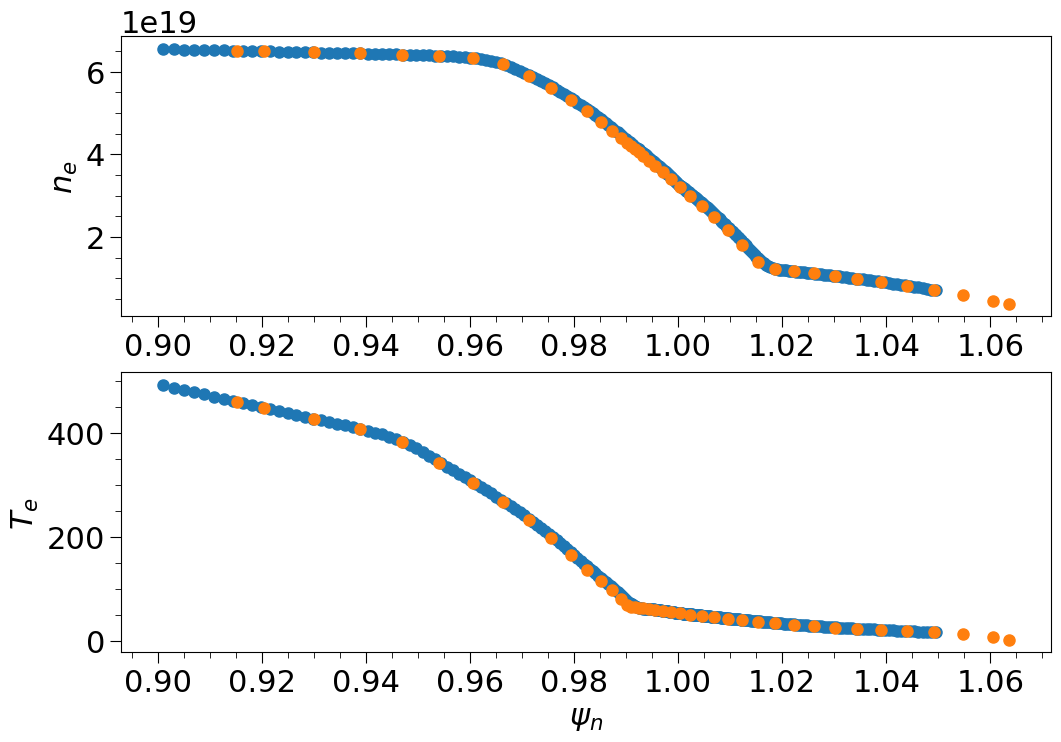

In [8]:
mapper = SIBIL_Midplane_Mapper(config)

In [9]:
type(mapper.bout)

sibil.grids.bout.Bout

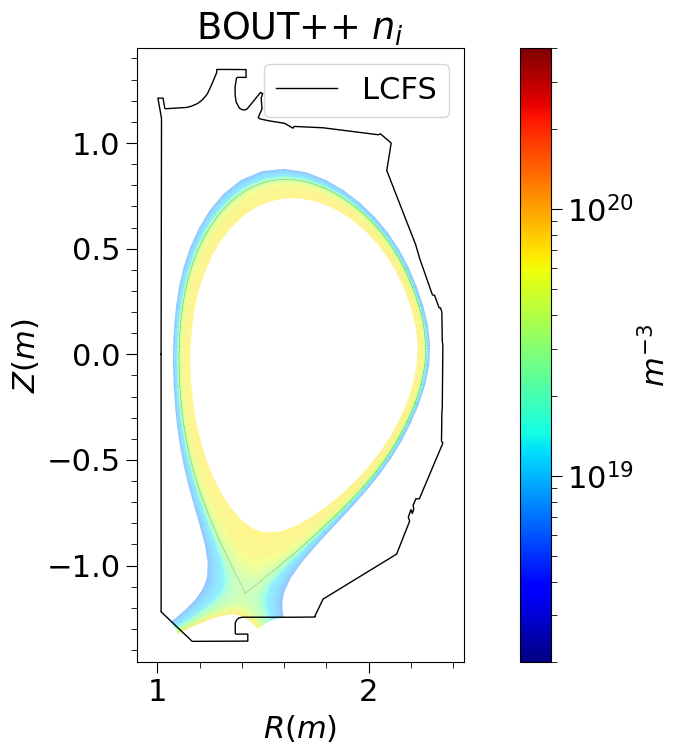

In [10]:
mapper.bout.plot_profile("ni")

In [11]:
convergent_transport_coeffs["Da_t"].shape

(15, 260, 64)

In [12]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Turn a 1-D radial transport-coefficient profile into a 2-D matrix shaped
like the SOLPS grid, by broadcasting it uniformly across the poloidal
(ny) direction. Produces this for both:

  1) the ORIGINAL SOLPS profile, i.e. tdata(2, j, k, l) as parsed by
     parse_tdata2, for a given (k, l) block, and
  2) the MODIFIED / interpolated profile, i.e.
     interplted_transport_coeffs[var_name] (the BOUT++-derived profile
     already interpolated onto sepx_dists_solps).

Both profiles are length N (the block size == mapper.solps.nx, fixed at
42 in this project), so both matrices come out as shape
(mapper.solps.nx, mapper.solps.ny) -- radially varying, poloidally
uniform -- which matches SOLPS's native (ix, jy) ordering, i.e. the SAME
convention mapper.solps already uses internally for fields like ni/Te.

WHY IT WAS BLANK BEFORE
------------------------
SOLPS grids are natively indexed (ix, jy), not (jy, ix). Static_grid's
plot_profile flattens SOLPS-ITER arrays with order="F" (Fortran order),
which is only correct if the array is shaped (nx, ny) -- radial index
varying fastest. Building the matrix as (ny, nx) and handing it to a
plotter that expects (nx, ny) with order="F" flattening doesn't raise
an error (the flattened length is still ny*nx), but it silently
scrambles which value lands on which polygon -- typically degenerating
to a near-constant/blank-looking fill.

IMPORTANT: use mapper.solps.nx / mapper.solps.ny here (nx=42 fixed,
matching the transport block length), NOT grid["nx"] / grid["ny"] read
directly from a raw SOLPS grid file -- those can differ (e.g. grid file
nx=260 including extra columns/guard cells).
"""
import numpy as np


def extract_original_tdata_profile(tdata2, k, l):
    """
    Pull tdata(2, j, k, l) for all j present, sorted by j, as an array.

    Returns
    -------
    j_idx : ndarray, sorted integer j indices found (1-based, as in file)
    values : ndarray, corresponding tdata values
    """
    entries = [(j, v) for (i, j, kk, ll), v in tdata2.items()
               if kk == k and ll == l]
    if not entries:
        raise KeyError(f"No tdata(2, j, k={k}, l={l}) entries found.")
    entries.sort(key=lambda t: t[0])
    j_idx = np.array([e[0] for e in entries])
    values = np.array([e[1] for e in entries])
    return j_idx, values


def broadcast_to_solps_grid(profile_1d, nx, ny):
    """
    Tile a 1-D radial profile (length N) into an (nx, ny) matrix -- SOLPS
    native (ix, jy) ordering -- uniform across the poloidal (ny)
    direction. N must equal nx.

    Each row i (radial index) is constant across all ny columns, i.e.
    profile_1d[i] is repeated across the whole poloidal extent.
    """
    profile_1d = np.asarray(profile_1d)
    if profile_1d.shape[0] != nx:
        raise ValueError(
            f"profile length {profile_1d.shape[0]} != mapper.solps.nx "
            f"({nx}). The profile must have exactly nx entries -- "
            f"broadcasting a mismatched-length array will silently "
            f"produce a blank plot instead of an error."
        )
    return np.tile(profile_1d.reshape(-1, 1), (1, ny))  # shape (nx, ny)


def build_original_and_modified_matrices(mapper, tdata2, interplted_transport_coeffs,
                                          coeff_kl):
    """
    Parameters
    ----------
    mapper : SIBIL_Midplane_Mapper
        Used only for mapper.solps.nx / mapper.solps.ny -- the actual
        grid dimensions the plotting code expects, in SOLPS-native
        (ix, jy) order.
    tdata2 : dict
        Output of parse_tdata2(INPUT_FILE).
    interplted_transport_coeffs : dict
        {var_name: 1-D array}, the BOUT++-derived / modified profiles,
        each of length mapper.solps.nx (42).
    coeff_kl : dict
        {var_name: (k, l)} -- which tdata(2, j, k, l) block corresponds
        to each entry in interplted_transport_coeffs. E.g.:
            coeff_kl = {"Da_t": (1, 1), "Xi_t": (3, 1), "Xe_t": (4, 1)}

    Returns
    -------
    original_matrices : dict[var_name] -> ndarray, shape (nx, ny)
    modified_matrices : dict[var_name] -> ndarray, shape (nx, ny)
    """
    nx = mapper.solps.nx
    ny = mapper.solps.ny

    original_matrices = {}
    modified_matrices = {}

    for var_name, (k, l) in coeff_kl.items():
        if var_name not in interplted_transport_coeffs:
            print(f"[skip] {var_name}: not found in interplted_transport_coeffs")
            continue

        modified_1d = np.asarray(interplted_transport_coeffs[var_name])

        try:
            _, original_1d = extract_original_tdata_profile(tdata2, k, l)
        except KeyError as e:
            print(f"[skip original] {var_name}: {e}")
            continue

        original_matrices[var_name] = broadcast_to_solps_grid(original_1d, nx, ny)
        modified_matrices[var_name] = broadcast_to_solps_grid(modified_1d, nx, ny)

    return original_matrices, modified_matrices

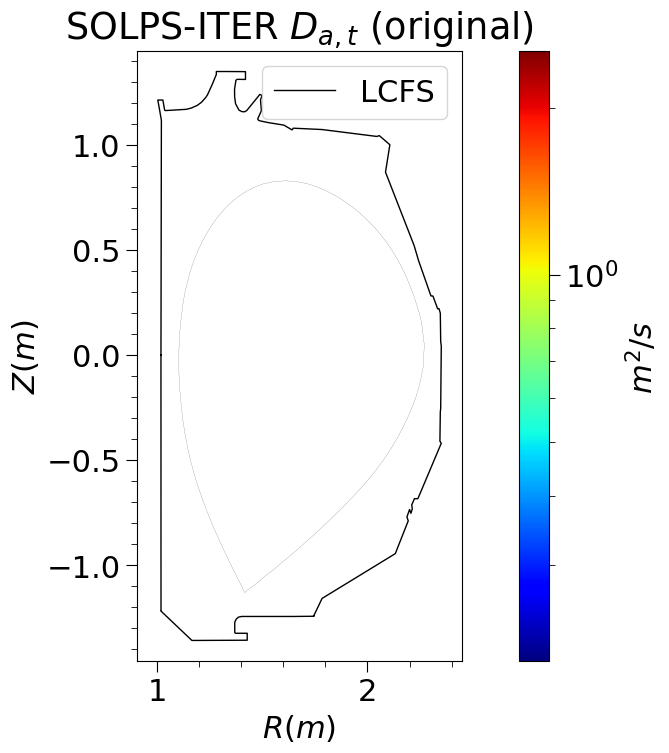

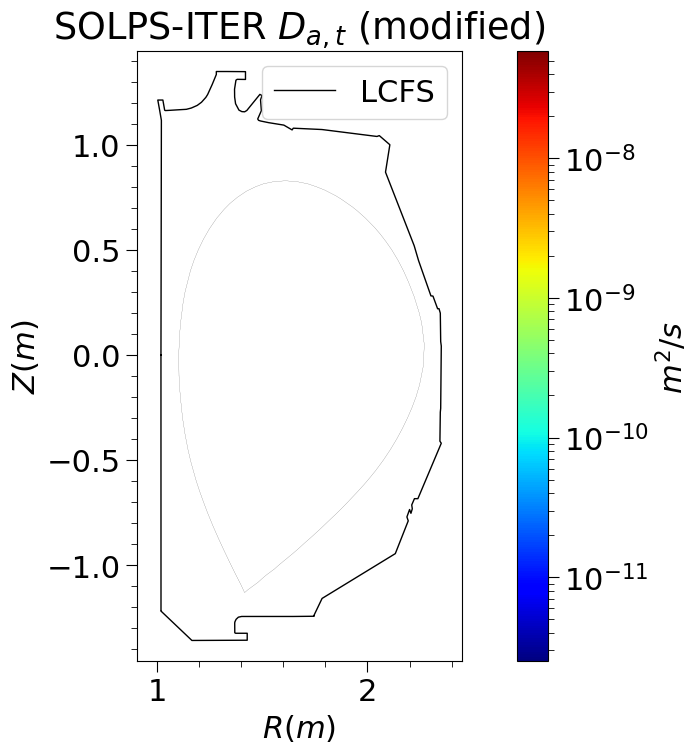

In [13]:

coeff_kl = {"Da_t": (1, 1), "Xi_t": (3, 1), "Xe_t": (4, 1)}  # adjust per your ls/k mapping

original_matrices, modified_matrices = build_original_and_modified_matrices(
    mapper, tdata2, interplted_transport_coeffs, coeff_kl
)

mapper.solps.plot_transport_coeff(
    original_matrices["Da_t"], name="$D_{a,t}$ (original)", unit="$m^2/s$", scale="log"
)
mapper.solps.plot_transport_coeff(
    modified_matrices["Da_t"], name="$D_{a,t}$ (modified)", unit="$m^2/s$", scale="log"
)